In [1]:
import sys
from pathlib import Path

# Add project root so `import shared` works
root = Path.cwd().resolve()
while root != root.parent and not (root / "shared").exists():
    root = root.parent
if not (root / "shared").exists():
    raise RuntimeError("Could not find project root containing 'shared/'")
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from shared.paths import get_experiment_paths
from shared.visualization import show_grid, save_grid

import torch
device = "cuda" if torch.cuda.is_available() else "cpu"

paths = get_experiment_paths("05_dcgan_fashionmnist")

In [2]:
def latest_ckpt(models_dir: Path):
    ckpts = sorted(models_dir.glob("ckpt_epoch_*.pth"))
    if not ckpts:
        raise FileNotFoundError(f"No ckpt_epoch_*.pth found in {models_dir}")
    return ckpts[-1]

In [4]:
import torch
import torch.nn as nn

In [5]:
z_dim = 100
feat = 64

class Generator(nn.Module):
    def __init__(self, z_dim=100, feat=64, img_channels=1):
        super().__init__()
        self.net = nn.Sequential(
            nn.ConvTranspose2d(z_dim, feat*4, 7, 1, 0, bias=False),
            nn.BatchNorm2d(feat*4),
            nn.ReLU(True),

            nn.ConvTranspose2d(feat*4, feat*2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(feat*2),
            nn.ReLU(True),

            nn.ConvTranspose2d(feat*2, feat, 4, 2, 1, bias=False),
            nn.BatchNorm2d(feat),
            nn.ReLU(True),

            nn.Conv2d(feat, img_channels, 3, 1, 1),
            nn.Tanh()
        )

    def forward(self, z):
        return self.net(z)

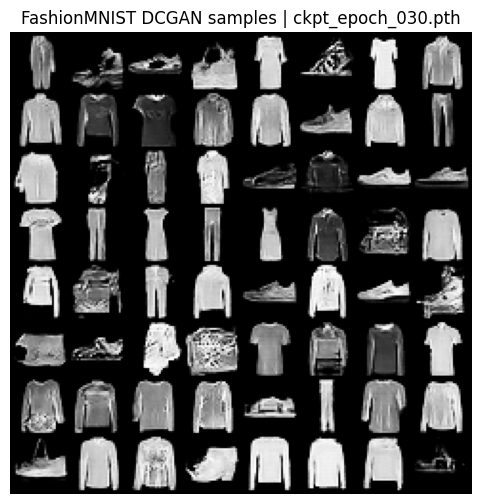

In [6]:
ckpt_path = latest_ckpt(paths.models_dir)
ckpt = torch.load(ckpt_path, map_location=device)

z_dim = ckpt.get("z_dim", 100)
feat = ckpt.get("feat", 64)

G = Generator(z_dim=z_dim, feat=feat).to(device)
G.load_state_dict(ckpt["G"])
G.eval()

with torch.no_grad():
    z = torch.randn(64, z_dim, 1, 1, device=device)
    samples = G(z)

show_grid(samples, title=f"FashionMNIST DCGAN samples | {ckpt_path.name}")